# Referral Saathi: whom to call first, and why

A health worker in rural India has a patient who needs dialysis, an emergency caesarean or trauma care. The
facility list she could search says many things that are not true: hospitals that "offer" a service because a
sentence about another hospital was pasted into their record, map points in the wrong district, and claims no one
has checked. **Referral Saathi** reads every listing sentence, keeps only evidence about the facility itself,
says how sure it is in words, and tells her whom to call first and why. It works offline and on a cheap phone.

This notebook is the code and the reasoning behind the app, in plain words first:

1. The problem and the data
2. What is wrong with the data
3. Cleaning: fixed, flagged, and what cannot be fixed
4. Sources and external evidence
5. The knowledge base
6. The model and an honest evaluation
7. `recommend(service, location)` with its WHY and HOW, on 3 real queries, including a multi-stop plan
8. Data stories
9. Limits
10. How to open the app

Every number below is computed in this notebook from the repository's files or the provided dataset, or copied
from a named report file by a function that fails if the report changes shape. Outputs show aggregate numbers,
charts and a few quoted facility sentences as examples. No table of the provided records is printed.

## 0. Setup

**On Databricks Free Edition:** clone the repository as a Git folder and open this notebook from `submission/`.
It reads the provided dataset from the Marketplace catalog through Spark. If you installed the listing under
another catalog name, change `CATALOG` below.

**Locally:** the same cells read the repository's cleaned tables in `derived/v1/` instead. Set `MODE` below to
force one or the other.

**Your own rebuild:** `00_rebuild_derived.ipynb` rebuilds `derived/v1` from the Marketplace table into a volume.
Put that folder (the one holding `derived/v1`, by default `/Volumes/workspace/referral_saathi/uploads/rebuild`) in
the `data_root` widget, or in the `DATATHON_ROOT` environment variable locally. Every table below and the app
builds then read your rebuild, and section 0.1 checks that it gives the same app as the repository's copy. Empty
means the repository's `derived/v1`.

Some steps cannot run inside Free Edition: the website crawl, web labelling and external downloads. They ran
offline. Their outputs are summary files in the repository, or tables in a Unity Catalog volume (`VOLUME`).
Each section that uses one says so.

In [1]:
import json
import math
import os
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

MODE = "auto"   # "auto", "databricks" or "local"
CATALOG = "databricks_virtue_foundation_dataset_dais_2026"
SCHEMA = "virtue_foundation_dataset"
VOLUME = f"/Volumes/{CATALOG}/referral_saathi/offline_outputs"   # created by the team for the offline steps

ON_DATABRICKS = MODE == "databricks" or (MODE == "auto" and "DATABRICKS_RUNTIME_VERSION" in os.environ)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "derived" / "v1").is_dir())
for p in (ROOT, ROOT / "app"):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

plt.rcParams.update({"figure.dpi": 100, "figure.figsize": (7, 3.2), "axes.spines.top": False,
                     "axes.spines.right": False})
# Where derived/v1 is read from: the data_root widget on Databricks, else DATATHON_ROOT, else this repository.
try:
    dbutils.widgets.text("data_root", "")  # noqa: F821 (dbutils is predefined on Databricks)
    DATA_ROOT = Path(dbutils.widgets.get("data_root") or os.environ.get("DATATHON_ROOT") or ROOT)  # noqa: F821
except NameError:
    DATA_ROOT = Path(os.environ.get("DATATHON_ROOT") or ROOT)
if not (DATA_ROOT / "derived" / "v1" / "MANIFEST.json").is_file():
    raise FileNotFoundError(f"{DATA_ROOT}/derived/v1/MANIFEST.json not found: check data_root")
os.environ["DATATHON_ROOT"] = str(DATA_ROOT)  # the app builds below (subprocesses) read the same folder
V1 = DATA_ROOT / "derived" / "v1"
REPO_URL = "https://github.com/LordKarV/databricksdatathon/blob/dev/"
print("running on", "Databricks" if ON_DATABRICKS else "a local machine", "| repository at", ROOT.name,
      "| derived/v1 from", "the repository" if DATA_ROOT == ROOT else DATA_ROOT)

running on a local machine | repository at wt63 | derived/v1 from the repository


The app reads small exports built from `derived/v1`, using only the standard library at run time. If they are
missing (a fresh clone), the next cell builds them. The order matters: the planner first, then the facts, whose
export copies the sentences the planner cites, then the "How this works" page data.

In [2]:
BUILDS = [("planner/out/planner_v1.json.gz", "planner/export_v1.py"),
          ("app/facts/out/facts.json.gz", "app/facts/build.py"),
          ("app/howto/out/how.json", "app/howto/build.py")]
for out, script in BUILDS:
    if (ROOT / out).is_file() and DATA_ROOT == ROOT:  # a rebuild in data_root: always build from it
        print(f"ok      {out}")
    else:
        r = subprocess.run([sys.executable, script], cwd=ROOT, capture_output=True, text=True, check=False)
        print(f"built   {out}: {r.stdout.strip().splitlines()[-1] if r.stdout.strip() else r.stderr[-300:]}")

ok      planner/out/planner_v1.json.gz
ok      app/facts/out/facts.json.gz
ok      app/howto/out/how.json


### 0.1 Check: does your rebuild give the same app?

Runs only when `data_root` points at a rebuild. It builds the app's facility facts and the 36 offline state packs
twice, from the repository's `derived/v1` and from yours, into a temporary folder, and compares them. The facts
hash covers every facility, pair, quote and score the app serves, but not the build time or the folder it was
read from. The packs are compared byte for byte with the same build date. PASS means a judge's rebuild drives
exactly the app we ship. Table-level checks against `MANIFEST.json` are in `00_rebuild_derived.ipynb`.

In [3]:
import tempfile


def app_build(data_root: Path, out: Path, built: str) -> dict:
    """Facts hash and per-state pack hashes, built from data_root/derived/v1 into out."""
    env = {**os.environ, "DATATHON_ROOT": str(data_root)}
    for script, args in (("app/facts/build.py", ["--out", str(out / "facts")]),
                         ("app/packs/build_packs.py", ["--out", str(out / "packs"), "--built", built])):
        r = subprocess.run([sys.executable, script, *args], cwd=ROOT, env=env, capture_output=True, text=True)
        if r.returncode != 0:
            raise RuntimeError(f"{script} failed on {data_root}: {r.stderr[-500:] or r.stdout[-500:]}")
    packs = json.loads((out / "packs" / "index.json").read_text())["packs"]
    return {"facts": (out / "facts" / "facts.sha").read_text().strip(),
            "packs": {k: v["sha256"] for k, v in packs.items()}}


if DATA_ROOT == ROOT:
    print("data_root is the repository: nothing to compare. Set data_root to your rebuild to run this check.")
else:
    built = json.loads((ROOT / "derived/v1/MANIFEST.json").read_text())["build_date"]
    with tempfile.TemporaryDirectory() as tmp:
        repo, mine = app_build(ROOT, Path(tmp) / "repo", built), app_build(DATA_ROOT, Path(tmp) / "mine", built)
    rows = [("facts (facilities, pairs, quotes, scores)", repo["facts"], mine["facts"])]
    rows += [(f"pack {k}", repo["packs"][k], mine["packs"].get(k, "missing")) for k in sorted(repo["packs"])]
    check = pd.DataFrame(rows, columns=["output", "from the repository", "from your rebuild"])
    check["result"] = (check["from the repository"] == check["from your rebuild"]).map({True: "PASS", False: "DIFF"})
    n_pass = int((check.result == "PASS").sum())
    print(f"{n_pass} of {len(check)} app outputs identical: {'PASS' if n_pass == len(check) else 'DIFF'}")
    display(check[check.result != "PASS"] if n_pass < len(check) else check.head(3))  # noqa: F821

data_root is the repository: nothing to compare. Set data_root to your rebuild to run this check.


## 1. The problem and the data

The provided dataset is one table of Indian health facilities, scraped from the web: names, addresses, map
points, phone numbers, and free-text lists of procedures, equipment, capabilities and specialties. A health
worker needs three facts from it, and it states none of them reliably:
- Does the facility exist?
- Is it where the map says?
- Does it really offer the service?

Local run: 9,959 usable records in derived/v1 (the cleaned copy of the provided table)


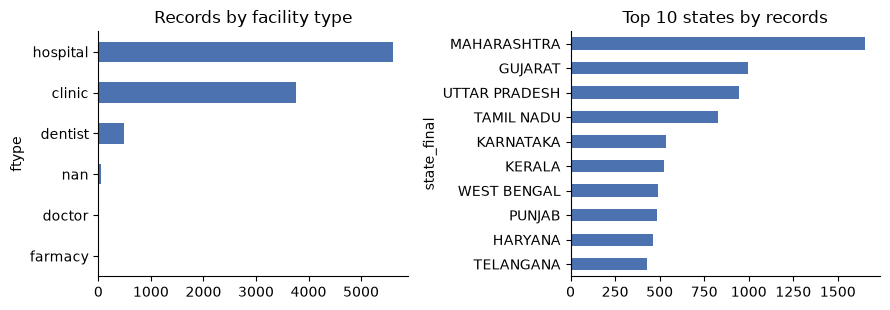

In [4]:
if ON_DATABRICKS:
    raw = spark.table(f"{CATALOG}.{SCHEMA}.facilities")  # noqa: F821 (spark is predefined on Databricks)
    n_records, n_columns = raw.count(), len(raw.columns)
    by_type = raw.groupBy("facilityTypeId").count().toPandas().set_index("facilityTypeId")["count"]
    by_state = (raw.groupBy("address_stateOrRegion").count().toPandas()
                .set_index("address_stateOrRegion")["count"])
    print(f"Provided table {CATALOG}.{SCHEMA}.facilities: {n_records:,} records, {n_columns} columns")
else:
    loc = pd.read_parquet(V1 / "facility_location.parquet", columns=["unique_id", "state_final"])
    # record counts by type for every usable record, as counted by the crawl's target builder
    by_type = pd.read_csv(ROOT / "kb/crawl/coverage_by_type.csv").set_index("ftype")["records"]
    n_records = len(loc)
    by_state = loc.state_final.value_counts()
    print(f"Local run: {n_records:,} usable records in derived/v1 (the cleaned copy of the provided table)")

fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
by_type.sort_values().tail(6).plot.barh(ax=ax[0], color="#4c72b0", title="Records by facility type")
by_state.sort_values().tail(10).plot.barh(ax=ax[1], color="#4c72b0", title="Top 10 states by records")
plt.tight_layout()
plt.show()

## 2. What is wrong with the data

We audited the table before cleaning it. These are the five findings that matter most for a patient. Each count
was checked by hand on samples; the full method is in `REPORT.md`. The table is copied from the report by
`app/howto/build.py`, the same function that feeds the app's "How this works" page, so the notebook and the app
cannot disagree.

In [5]:
from howto import build as how


def show_table(t, cols=None, max_chars=140):
    df = pd.DataFrame(t["rows"], columns=t["columns"])
    if cols:
        df = df[cols]
    with pd.option_context("display.max_colwidth", max_chars):
        display(df)
    print(f"source: {t['source']}, section '{t['heading']}'")

findings = how.table("REPORT.md", "1.1 The 5 findings", ["Finding", "Verified count / denominator",
                                                      "What goes wrong for a patient"])
show_table(findings)

,Finding,Verified count / denominator,What goes wrong for a patient
0,Records hold text about another facility (merged records),"About 1,405 / 9,959 name another facility (about 14%); about 5% are harmful misattributions. Other-district mentions: 23 of 30 sampled w...","Sent to an eye hospital for dialysis because a Delhi government hospital's sentence sits in its record (Aravind), or to Nagpur for servi..."
1,"Listing coordinates are often in the wrong town, usually in the right state","1,407 / 9,682 more than 50 km from their own PIN (1,114 more than 100 km); 1,340 of the 1,407 stay in the same state. Coordinates follow...","Told a hospital is 5 km away when it is 300 km away (HOSMAT Bangalore is placed at Gadag, about 350 km off), or never shown the nearest ..."
2,"""Strong-looking"" evidence is often only wording or a label",Strong dialysis grades whose prerequisite is met by the claim sentence itself: 345 / 355. Trauma sentences with explicit trauma wording:...,"A one-word list item or a specialty tag ranks like a staffed unit; a highway trauma case goes to a nursing home with ""24/7 emergency care"""
3,"The ""official"" phone often reaches a directory or call centre","+919693969347 sits on 431 records in 37 state strings and is the officialPhone of 87. 348 / 9,464 officialPhones are held by records in ...","The health worker calls to confirm a bed and reaches a real-estate or booking line, in an emergency"
4,Typed locations are ambiguous or silently wrong,"5 / 40 realistic inputs are district names in two states (Aurangabad, Bilaspur, Hamirpur, Pratapgarh, Balrampur); ""Hydrabad"" silently re...","A worker in Bihar typing ""Aurangabad"" gets Maharashtra hospitals about 1,000 km away"


source: REPORT.md, section '1.1 The 5 findings'


One of those findings, recomputed here from the cleaned location table: how far each record's map point is from the centre of its own PIN code.

1,367 of 9,869 map points are more than 50 km from their own PIN code (1,101 more than 100 km).


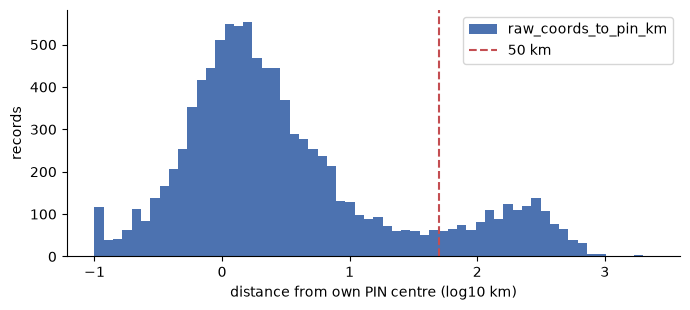

In [6]:
d = pd.read_parquet(V1 / "facility_location.parquet", columns=["raw_coords_to_pin_km"]).raw_coords_to_pin_km.dropna()
far50, far100 = int((d > 50).sum()), int((d > 100).sum())
print(f"{far50:,} of {len(d):,} map points are more than 50 km from their own PIN code ({far100:,} more than 100 km).")
ax = d.clip(lower=0.1).map(math.log10).plot.hist(bins=60, color="#4c72b0")
ax.axvline(math.log10(50), color="#c44e52", ls="--", label="50 km")
ax.set_xlabel("distance from own PIN centre (log10 km)")
ax.set_ylabel("records")
ax.legend()
plt.tight_layout()
plt.show()

## 3. Cleaning: fixed, flagged, and what cannot be fixed

Cleaning does three different things, and the app treats them differently:
- **Fixed:** repaired in `derived/v1`.
- **Flagged:** kept, but shown to the user as a warning on the card.
- **Cannot be fixed by cleaning:** the answer is a phone call before travelling, and the app says so.

In [7]:
fixed, flagged, cannot = (how.table("REPORT.md", h) for h in ("Fixed", "Flagged", "Cannot be handled by cleaning"))
print(f"fixed: {len(fixed['rows'])} problems | flagged: {len(flagged['rows'])} | cannot be fixed by cleaning: "
      f"{len(cannot['rows'])}")
show_table(cannot)

fixed: 20 problems | flagged: 15 | cannot be fixed by cleaning: 5


,Issue,Size,Mitigation
0,Anonymous copied text (names no facility),"7,514 service sentences in 1,390 records; 1,161 of 4,151 v2 strong grades sit in such records; 0 of 20 hand-read sentences looked foreign","Record-level warning, ""call first"" default, field-call ledger. Optional offline ai_query attribution that can only lower a grade (specif..."
1,Merged multi-place records,"About 1,370 to 1,400 records","Not split; flags, second point, ""phone before travelling"""
2,Arrays truncated at 50 items,"1,495 records, 4,498 pairs","""A missing service may still exist"""
3,Merges where every field follows the other facility,Not countable,None in the data; only a phone call
4,Thin rural coverage,"Bihar: 260 of 9,959 records, 146 in Patna district",Coverage note on every result


source: REPORT.md, section 'Cannot be handled by cleaning'


In [8]:
show_table(fixed, max_chars=90)

,Issue,Before,After,Residual risk
0,Exact duplicate rows,"9,970 rows","9,959 records",None
1,Busy PINs far from facility consensus,"78 of 1,051 more than 25 km off (422009 Nashik 167.5 km)","43 of 1,051 (422009 now 2.5 km); 69 PINs overridden",Uses facility points to fix PIN points (circular in principle)
2,PINs misplaced inside small districts (403513 Pernem at sea),31 PINs wrong,31 moved to district median (radius 25 km),"Untuned 60 km, 3x rule"
3,Facility PINs missing from directory,134 PINs with no point,"127 have a point (14 consensus, 113 prefix median at 50 km radius)",Prefix point is district-level only
4,Coordinates outside India,6 used for distance,0 used; 9 marked city-level,Small
5,10 to 50 km band (mostly centroid imprecision),"1,081 records",718 records,"Some real errors labelled ""approximate"""
6,Stated state unusable for a filter,82 unresolved,32 unresolved; 0 records without a filter state,Pre-2014 Andhra labels stay flagged
7,District and NFHS join,"9,961 / 9,970 with 2 wrong joins","9,946 districts; 9,934 NFHS joins; 12 empty by design",Parent-district figures for split districts
8,Typed location input,38 of 40 audit tests; Hydrabad silent; homonyms auto-picked,54 of 54 on an extended self-written suite,"Regression suite, not an accuracy estimate"
9,Residual duplicates,0 linked,75 groups (152 records) shown as one card; 52 soft links; 17 co-located units,"In-sample: hard merge precision 0.84, recall 0.90 on the labels it was shaped on"


source: REPORT.md, section 'Fixed'


The core of the cleaning is sentence attribution. Every listing sentence is split out with an id, then tagged:
- about this facility (`own_anchored`);
- about another facility (`other_facility`, often copied from a group or a directory page);
- ambiguous;
- or unanchored (a plain service phrase with no name in it).

Only sentences about the facility itself, or unanchored sentences, count as evidence. The others are listed as
ignored.

469,498 listing sentences; 9,506 name another facility and never count as evidence for this one.


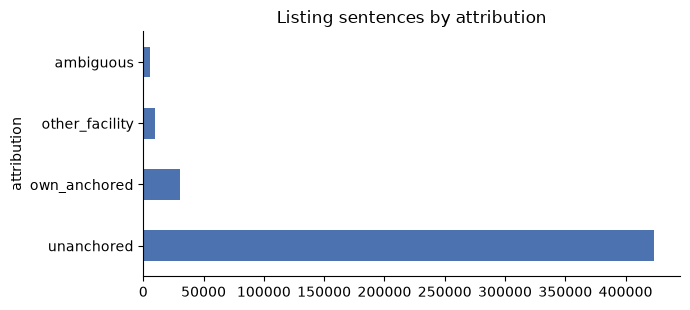

In [9]:
claims = pd.read_parquet(V1 / "claims.parquet", columns=["attribution"])
att = claims.attribution.value_counts()
print(f"{len(claims):,} listing sentences; {att.get('other_facility', 0):,} name another facility and never count "
      "as evidence for this one.")
att.plot.barh(color="#4c72b0", title="Listing sentences by attribution")
plt.tight_layout()
plt.show()

## 4. Sources and external evidence

Every record was scraped from web pages: social media pages, insurance-scheme lists, directories, the facility's
own website. We scored how often each kind of source was right, against claims confirmed or contradicted by a
second source. The reliability and its 90% interval come from `derived/v1/source_classes.csv`.

158,444 source URLs in 16 classes


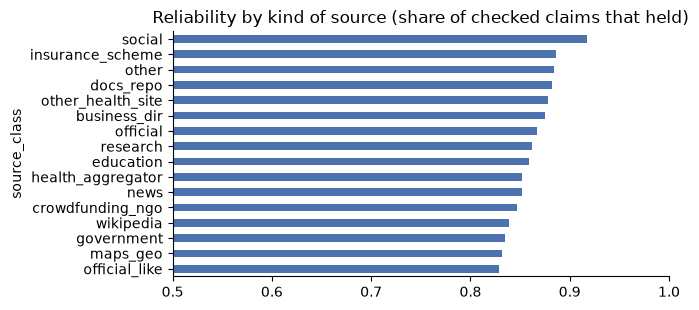

In [10]:
sc = pd.read_csv(V1 / "source_classes.csv").sort_values("n_urls", ascending=False)
print(f"{sc.n_urls.sum():,} source URLs in {len(sc)} classes")
ax = sc.set_index("source_class").reliability.sort_values().plot.barh(
    xerr=None, color="#4c72b0", title="Reliability by kind of source (share of checked claims that held)")
ax.set_xlim(0.5, 1)
plt.tight_layout()
plt.show()

We evaluated 14 public lists as independent evidence (accreditation, blood centres, maternity certification,
OpenStreetMap and others), with a hand check of the match quality and the licence of each for a public demo.
Restricted lists are used only as per-facility facts and are never printed here.

In [11]:
show_table(how.table("research/DATASETS.md", "Summary", ["Dataset", "Role", "Licence for a public demo",
                                                        "Hand check"]))

,Dataset,Role,Licence for a public demo,Hand check
0,NABH accredited list,"evidence, labels",restricted (per-facility facts only),39/40
1,LGD archive (PIN to district),geography,"reproduce freely, credit LGD","19/20, 1 ambiguous"
2,PIN code boundaries,"geography, location check",GODL,"12/12, far flag 4/4"
3,IDP NFHS district (NFHS-5 and NFHS-6),need,ODC-BY,20/20
4,MAP travel time to healthcare,travel time,CC BY,20/20 raster values
5,NMC medical colleges and courses,"evidence, labels",restricted (per-facility facts only),19/20
6,e-RaktKosh blood centres,"evidence, routing, labels",no licence stated,"16/20 strict, 18/20 with likely"
7,LaQshya certification,"evidence, labels (maternity)","NHSRC: reproduce freely, credit","17/20 plus 3 plausible, 0 wrong"
8,HOT OSM health facilities,existence and location evidence,"ODbL, share-alike",15/20 (0 wrong among unflagged)
9,MoHFW trauma care facilities (196),"evidence, routing, labels (trauma)",restricted (per-facility facts only),19/20


source: research/DATASETS.md, section 'Summary'


Two offline witnesses add independent text and tags. Neither can run inside Free Edition: the crawl needs
outbound HTTP for about an hour, and the matching needs large downloads. Their summaries are committed in `kb/`.

In [12]:
crawl = json.loads((ROOT / "kb/crawl/crawl_stats.json").read_text())
osm = json.loads((ROOT / "kb/opendata/stats.json").read_text())
print(f"Website crawl: {crawl['sites_reachable']:,} of {crawl['sites_attempted']:,} facility websites reachable "
      f"({crawl['runtime']['minutes_total']} minutes over {crawl['runtime']['runs']} runs).")
cov = osm["coverage"]
print(f"Open data: {cov['any_match']['n']:,} of {osm['vf_facilities']:,} records matched to OpenStreetMap or "
      f"Wikidata ({cov['any_match']['share_of_vf']:.0%}); opening hours parsed for {cov['hours_parsed']['n']:,}.")

Website crawl: 6,127 of 9,037 facility websites reachable (51.5 minutes over 9 runs).
Open data: 2,844 of 9,959 records matched to OpenStreetMap or Wikidata (29%); opening hours parsed for 134.


## 5. The knowledge base

- **Taxonomy** (`kb/taxonomy/lexicon.json`): the services, the phrases that count as evidence for each, and the
  prerequisites a real unit needs. For example, dialysis needs a nephrologist or a dialysis machine.
- **Evidence rules** (`derived/v1/evidence_rules.parquet`): how strong each pattern of evidence is, checked by
  hand on real cases.
- **Care pathways** (`kb/pathways/care_pathways.json`): for time-critical cases, which kind of facility to reach
  first and within how long, each step quoted from a guideline or marked as an assumption.

37 services in the taxonomy; 20 evidence rules from 292 hand-checked cases; 10,799 facility-service pairs graded.
Care pathways: Heart attack (STEMI); Major trauma; Obstetric emergency including emergency caesarean; Burns; Sick newborn; Snakebite; Starting maintenance dialysis


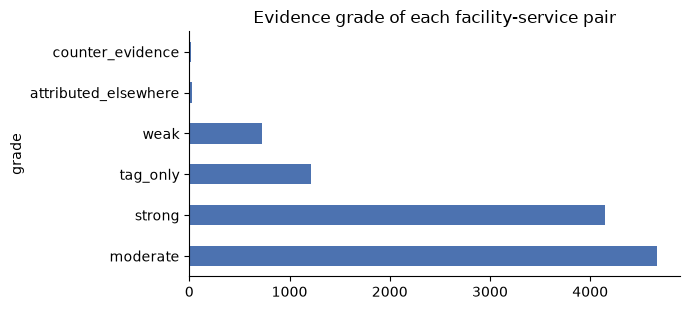

In [13]:
lex = json.loads((ROOT / "kb/taxonomy/lexicon.json").read_text())
rules = pd.read_parquet(V1 / "evidence_rules.parquet")
grades = pd.read_parquet(V1 / "grades.parquet", columns=["grade"])
pathways = json.loads((ROOT / "kb/pathways/care_pathways.json").read_text())["pathways"]
print(f"{len(lex['services'])} services in the taxonomy; {len(rules)} evidence rules from "
      f"{int((rules.handcheck_true + rules.handcheck_false).sum())} hand-checked cases; "
      f"{len(grades):,} facility-service pairs graded.")
print("Care pathways:", "; ".join(p["name"].split(":")[0] for p in pathways))
grades.grade.value_counts().plot.barh(color="#4c72b0", title="Evidence grade of each facility-service pair")
plt.tight_layout()
plt.show()

## 6. The model and an honest evaluation

> **To be completed by the team lead after #11** (the fitted model). This section will load the fitted scores
> (`derived/v2/facility_service_scores.parquet`) and print the final evaluation.

Until then, the app uses an interim, conservative rule. It says "Likely" only when a second source confirmed the
service; everything else is "Not verified: call first". Below is the current measured evaluation of the
prototype model, including the baselines and an LLM judge, copied from `model/MODEL_SPEC.md`.

In [14]:
show_table(how.table("model/MODEL_SPEC.md", "4.2 Pair-level discrimination",
                     ["system", "all 71 test", "searched only (39, 17 pos)"]))

,system,all 71 test,"searched only (39, 17 pos)"
0,WL shipped,"0.776 [0.680, 0.862]","0.711 [0.614, 0.810]"
1,B0 any mention,"0.560 [0.471, 0.647]","0.548 [0.444, 0.652]"
2,B1 keyword count,"0.712 [0.590, 0.839]","0.697 [0.556, 0.837]"
3,B2 rule grade,"0.697 [0.580, 0.826]","0.693 [0.569, 0.823]"
4,B3 LLM judge (llama-3.3-70b),"0.585 [0.486, 0.685]","0.533 [0.416, 0.644]"
5,"B4 prior only (M1, unfitted)","0.789 [0.692, 0.875]","0.754 [0.639, 0.864]"
6,B5 gold only (M0),"0.687 [0.566, 0.795]","0.655 [0.569, 0.750]"
7,stratum label alone,"0.671 [0.562, 0.796]","0.673 [0.548, 0.802]"


source: model/MODEL_SPEC.md, section '4.2 Pair-level discrimination'


In [15]:
did_not = how.bullets("model/MODEL_SPEC.md", "4.11 Claims that did not survive review")
print("What did not work (from the statistical review):\n")
for x in did_not["items"][:5]:
    print(" -", x[:230] + ("..." if len(x) > 230 else ""))
print(f"\n... {len(did_not['items'])} in all, in {did_not['source']}")

What did not work (from the statistical review):

 - "The fitted scorecard beats the baselines." Only against B0, B3 and B5 do the intervals exclude 0. The unfitted expert ledger B4 does at least as well: -0.013 [-0.076, 0.048] raw on all 71; fusion's own IPW comparison on the searc...
 - "Likely carries a precision guarantee." The band is empty on test.
 - "P_S is calibrated." IPW ECE is 0.197, and P_S tracks searchability as well as truth.
 - "Evidence on heavily merged records earns visibly less weight." The bucket discounts tb_mid and tb_high were fitted to 0 at their bound. The free main effects are positive (g_mid +1.055, g_high +0.460 before Platt), so records bui...
 - "More own text means more confidence." Steps t2 and t3 are 0, and t4 is cancelled for 4 of 7 services. Three sentences in three fields earn what one any-mention tag earns. Among the text steps only t1 (+0.754) and t5 (+1.075) are ...

... 10 in all, in model/MODEL_SPEC.md


## 7. `recommend(service, location)`: the answer, its WHY and its HOW

This is the same code the app serves at `POST /api/plan`, imported from `app/`:
- `facts.engine.Engine`: the scores, bands and evidence for each facility and service;
- `itinerary`: the multi-stop route from `planner/`.

For each option it prints:
- the band in words, the score with its range, and the travel estimate;
- the listing's own sentences, word for word, with their ids;
- the points that add up to the score;
- the question to ask on the phone.

In [16]:
from facts.engine import RULE_PLAIN, Engine
from itinerary import attach

ENGINE = Engine.load()
print(f"engine loaded: {len(ENGINE.fid):,} facilities, {sum(len(v) for v in ENGINE.pairs.values()):,} "
      f"facility-service pairs, {len(ENGINE.claims):,} quotable sentences; data {ENGINE.meta['source']} "
      f"as of {ENGINE.meta['as_of']}")

def recommend(service: str, lat: float, lon: float) -> dict:
    """The /api/plan payload for a service at a point (rounded to about 1 km, as the app does)."""
    return attach(ENGINE.plan(service, round(lat, 2), round(lon, 2), None, "notebook"), ENGINE)

def show(plan: dict, n: int = 3) -> None:
    label = plan["query"]["service_label"]["en"]
    print(f"== {label} near {plan['location']['lat']}, {plan['location']['lon']}")
    if plan["abstain"]:
        print("   SAYS NO:", plan["abstain"]["text"])
    for o in plan["options"][:n]:
        t = o["travel"]
        print(f"\n{o['rank']}. {o['name']} ({o['district']}, {o['state']})")
        print(f"   {o['band_word'].upper()}: score {o['p']:.2f} (range {o['p_lo']:.2f} to {o['p_hi']:.2f}); "
              f"{t['km']:.0f} km, about {t['low']}-{t['high']} min ({t['label']})")
        for e in o["evidence"][:2]:
            print(f'   WHY  "{e["quote"]}"  [{e["claim_id"]}]')
        pts = " + ".join(f"{c['label']} {c['points']:+d}" for c in o["contributions"])
        print(f"   HOW  {pts} = {sum(c['points'] for c in o['contributions']):+d} points")
        if o.get("why_first_text"):
            print("   FIRST", o["why_first_text"])
        print("   ASK ", o["call_ahead"][0]["question"])
    it = plan.get("itinerary")
    if it and it["plans"]:
        r = it["plans"][0]
        print(f"\n   ROUTE ({it['pathway_name']}): {r['type_word']}")
        for k, s in enumerate(r["stops"], 1):
            print(f"   {k}. {s['purpose_word']}: {s['name']}, arrive about {s['eta_low']}-{s['eta_high']} min, "
                  f"chance {s['p']:.2f}, {s['n_evidence']} evidence lines")
        if r["vs_direct"]:
            v = r["vs_direct"]
            print(f"   vs going straight to {v['direct_name']} ({v['direct_minutes']} min): chance of care in time "
                  f"{v['direct_p_objective']:.2f} direct against {v['plan_p_objective']:.2f} with this route")

engine loaded: 9,947 facilities, 7,980 facility-service pairs, 44,968 quotable sentences; data derived/v1 as of 2026-11-21


In [17]:
show(recommend("dialysis", 24.79, 85.0))          # Gaya, Bihar

== dialysis near 24.79, 85.0

1. Arsh Superspeciality Hospital (GAYA, BIHAR)
   LIKELY: score 0.99 (range 0.82 to 0.93); 2 km, about 2-3 min (rough estimate: straight line x 1.34 at 49 km/h, no route check)
   WHY  "Dialysis"  [242efdf5:proc:15]
   HOW  model score (derived/v2) +49 = +49 points
   ASK  Do you have dialysis unit or machine on site?

2. Buddha Hospital and Research Institute (GAYA, BIHAR)
   LIKELY: score 0.93 (range 0.82 to 0.93); 5 km, about 4-9 min (rough estimate: straight line x 1.34 at 49 km/h, no route check)
   WHY  "Dialysis"  [3732a3f9:proc:10]
   WHY  "Hemodialysis machines"  [3732a3f9:equi:7]
   HOW  model score (derived/v2) +26 = +26 points
   ASK  Do you have dialysis unit or machine on site?

3. Nirog Hospital (PATNA, BIHAR)
   NOT VERIFIED: score 0.86 (range 0.82 to 0.93); 81 km, about 58-91 min (rough estimate: straight line x 1.30 at 71 km/h, no route check)
   WHY  "Provides dialysis treatment at City Dialysis Centre, a unit of Nirog Hospital"  [d460ac

In [18]:
show(recommend("emergency_csection", 19.88, 75.34))   # Aurangabad district, Maharashtra

== emergency C-section near 19.88, 75.34

1. United CIIGMA Hospital (AURANGABAD, MAHARASHTRA)
   LIKELY: score 0.88 (range 0.82 to 0.93); 3 km, about 3-6 min (rough estimate: straight line x 1.34 at 49 km/h, no route check)
   WHY  "Offers labour analgesia and Caesarean sections"  [231f141f:proc:14]
   HOW  model score (derived/v2) +20 = +20 points
   ASK  What does it cost? Is PM-JAY accepted?

2. Janaki Hospital (AURANGABAD, MAHARASHTRA)
   LIKELY: score 0.76 (range 0.67 to 0.90); 4 km, about 4-7 min (rough estimate: straight line x 1.34 at 49 km/h, no route check)
   WHY  "Caesarean section"  [6a4edbdd:proc:3]
   HOW  model score (derived/v2) +12 = +12 points
   ASK  What does it cost? Is PM-JAY accepted?

3. Runwal Accident and Maternity Hospital (JALNA, MAHARASHTRA)
   LIKELY: score 0.86 (range 0.82 to 0.93); 75 km, about 54-85 min (rough estimate: straight line x 1.30 at 70 km/h, no route check)
   WHY  "Provides normal vaginal delivery and caesarean delivery"  [4afa8b92:proc:5]


In [19]:
show(recommend("trauma_emergency", 25.15, 83.68))     # NH-19 near Mohania, Bihar: a multi-stop plan

== accident and injury care near 25.15, 83.68

1. Sharda Hospital (CHANDAULI, UTTAR PRADESH)
   NOT VERIFIED: score 0.81 (range 0.82 to 0.93); 55 km, about 41-66 min (rough estimate: straight line x 1.30 at 67 km/h, no route check)
   WHY  "Pediatric trauma care."  [7e420f3f:proc:4]
   WHY  "24/7 emergency care"  [7e420f3f:capa:0]
   HOW  model score (derived/v2) +15 = +15 points
   ASK  Can you do accident and injury care today?

2. Heritage Hospitals (VARANASI, UTTAR PRADESH)
   LIKELY: score 0.96 (range 0.82 to 0.93); 90 km, about 63-99 min (rough estimate: straight line x 1.30 at 72 km/h, no route check)
   WHY  "24/7 emergency care"  [390fa6ee:capa:11]
   WHY  "Trauma centre for orthopedic injuries"  [390fa6ee:capa:12]
   HOW  model score (derived/v2) +33 = +33 points
   ASK  What does it cost? Is PM-JAY accepted?

3. Ford Hospital (VARANASI, UTTAR PRADESH)
   LIKELY: score 0.96 (range 0.82 to 0.93); 89 km, about 63-98 min (rough estimate: straight line x 1.30 at 72 km/h, no route

## 8. Data stories

In [20]:
stories = ROOT / "viz" / "STORYBOOK.md"
if stories.is_file():
    heads = [ln.lstrip("# ").strip() for ln in stories.read_text().splitlines() if ln.startswith("## ")]
    print("Data stories in viz/STORYBOOK.md:")
    for head in heads:
        print(" -", head)
else:
    print("The data stories (issue #53) are not in this version yet; this cell lists them once viz/ lands.")

Data stories in viz/STORYBOOK.md:
 - The arc at a glance
 - Act 1. The problem: data you cannot trust
 - Act 2. What we measured
 - Act 3. How we built trust
 - Act 4. How the model decides
 - Act 5. Impact: deserts, golden hour, journeys
 - Act 6. Limits
 - Five charts for the app's "How this works" page
 - Cross-chart consistency
 - Numbers that differ between stories
 - Bench: strong stories not in the 15
 - What this step ran and did not run


## 9. Limits

In [21]:
h = json.loads((ROOT / "app/howto/out/how.json").read_text())["facts"]
print(f"- Thin rural coverage: {h['bihar_records']['value']:,} of {h['bihar_records']['of']:,} records are in Bihar.")
print(f"- Only {h['app_likely']['value']} of {h['app_pairs']['value']:,} facility-service pairs the app serves are "
      "confirmed by a second source; everything else is 'call first'.")
print("- Labels come from public web pages, not from phone calls or visits.")
print(f"- Opening hours: {h['hours_records']['value']:,} of {h['hours_records']['of']:,} records mention hours at all; "
      "nothing says whether a bed or a slot is free today.")
print("- Travel times are rough estimates (straight line times a road factor), shown as ranges.")

- Thin rural coverage: 260 of 9,959 records are in Bihar.
- Only 45 of 7,980 facility-service pairs the app serves are confirmed by a second source; everything else is 'call first'.
- Labels come from public web pages, not from phone calls or visits.
- Opening hours: 4,320 of 9,959 records mention hours at all; nothing says whether a bed or a slot is free today.
- Travel times are rough estimates (straight line times a road factor), shown as ranges.


## 9b. Learning from phone calls (reviewed, never automatic)

When a health worker taps "Said yes", "Said no" or "No answer" after calling, the app writes one row to
`workspace.referral_saathi.call_outcomes`. A row holds the facility, the service, the answer, the call questions,
the model version, the district and the time. It never holds patient data.

The cell below reads those rows and shows how they *would* move the weight of each evidence family. It uses a
Beta update: the family's mean score today counts as 10 earlier calls, and each answered call adds one more. Nothing
is retrained from here; a person reviews the table first.

In [22]:
from collections import defaultdict

OUTCOMES_TABLE = "workspace.referral_saathi.call_outcomes"
PRIOR_CALLS = 10
rows = []
if ON_DATABRICKS:
    try:
        q = f"SELECT facility_id, service_id, outcome, count(*) AS n FROM {OUTCOMES_TABLE} GROUP BY ALL"
        rows = [tuple(r) for r in spark.sql(q).collect()]  # noqa: F821 (spark is predefined on Databricks)
    except Exception as e:  # table missing in this workspace
        print("call_outcomes is not readable here:", type(e).__name__)
if not rows:
    print("No call outcomes recorded in this environment yet; the table below fills in as calls are recorded.")

fam = defaultdict(lambda: {"yes": 0, "no": 0, "no_answer": 0, "score_sum": 0.0, "pairs": 0})
for rule_rows in ENGINE.pairs.values():
    for p in rule_rows:
        fam[p.rule]["score_sum"] += p.score
        fam[p.rule]["pairs"] += 1
for fid, sid, outcome, n in rows:
    i = ENGINE.fid.get(fid)
    p = ENGINE.index.get(sid, {}).get(i) if i is not None else None
    if p is not None:
        fam[p.rule][outcome] += int(n)
print(f"{'evidence family':52} {'pairs':>6} {'yes':>4} {'no':>4} {'mean now':>9} {'would be':>9}")
for rule, f in sorted(fam.items(), key=lambda kv: -kv[1]["pairs"]):
    mean = f["score_sum"] / f["pairs"]
    new = (mean * PRIOR_CALLS + f["yes"]) / (PRIOR_CALLS + f["yes"] + f["no"])
    label = RULE_PLAIN.get(rule, rule)[:52]
    print(f"{label:52} {f['pairs']:>6,} {f['yes']:>4} {f['no']:>4} {mean:>9.2f} {new:>9.2f}")

No call outcomes recorded in this environment yet; the table below fills in as calls are recorded.
evidence family                                       pairs  yes   no  mean now  would be
an own sentence about it                              3,833    0    0      0.78      0.78
own specific sentences about it                       2,862    0    0      0.91      0.91
only a specialty or tag list                            723    0    0      0.33      0.33
only a general sentence                                 260    0    0      0.76      0.76
its name suggests a different specialty                 258    0    0      0.60      0.60
its sentence names another facility                      25    0    0      0.24      0.24
a sentence says it is not offered                        19    0    0      0.21      0.21


## 10. How to open the app

The app runs as a Databricks App, `referral-saathi`, in the team's workspace. Judges get access as workspace
users. It is built for a phone:
- **Start:** tap a service; the app uses GPS, or a PIN code, village or district.
- **Results:** whom to call first, with the evidence on each card; "Why this?" opens the full WHY and HOW.
- **Offline:** after one online visit, the state's facility data is saved and answers keep working without
  internet.
- **"How this works":** in the header, this notebook's story in plain words.

To run it locally: `.venv-app/bin/python -m uvicorn app:app` from `app/` (see `app/README.md`).

## Appendix: all our code

Every Python module in the repository, by folder, with a link. The notebook imports `app/`, `planner/`, `geo/`
and `app/howto/` directly. The rest are the offline pipelines that produced `derived/v1` and the `kb/`
summaries.

In [23]:
from IPython.display import Markdown

SKIP = {".venv-app", ".venv", "node_modules", "build", "out", "__pycache__", ".git", ".claude"}
try:  # tracked files only, so every link resolves on GitHub; plain folder walk where git is not available
    tracked = subprocess.run(["git", "ls-files", "*.py"], cwd=ROOT, capture_output=True, text=True, check=True)
    mods = sorted(Path(x) for x in tracked.stdout.split())
except (OSError, subprocess.CalledProcessError):
    mods = sorted(p.relative_to(ROOT) for p in ROOT.rglob("*.py") if not SKIP & set(p.relative_to(ROOT).parts))
by_dir = {}
for m in mods:
    by_dir.setdefault(m.parts[0], []).append(m)
lines = [f"{len(mods)} modules in {len(by_dir)} top-level folders.\n"]
for top, ms in by_dir.items():
    lines.append(f"**{top}/** ({len(ms)}): " + ", ".join(f"[{m.relative_to(top) if len(m.parts) > 1 else m}]"
                                                         f"({REPO_URL}{m.as_posix()})" for m in ms))
Markdown("\n\n".join(lines))

612 modules in 18 top-level folders.


**app/** (42): [app.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app/app.py), [checks/a11y_check.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app/checks/a11y_check.py), [facts/__init__.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app/facts/__init__.py), [facts/build.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app/facts/build.py), [facts/engine.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app/facts/engine.py), [facts/redact.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app/facts/redact.py), [howto/__init__.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app/howto/__init__.py), [howto/build.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app/howto/build.py), [inputs/__init__.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app/inputs/__init__.py), [inputs/build_lexicon.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app/inputs/build_lexicon.py), [inputs/understand.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app/inputs/understand.py), [itinerary.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app/itinerary.py), [main.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app/main.py), [outcomes.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app/outcomes.py), [packs/build_packs.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app/packs/build_packs.py), [services.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app/services.py), [stories/__init__.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app/stories/__init__.py), [stories/build.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app/stories/build.py), [stub_data.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app/stub_data.py), [tests/test_api.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app/tests/test_api.py), [tests/test_engine.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app/tests/test_engine.py), [tests/test_faithfulness.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app/tests/test_faithfulness.py), [tests/test_hindi_lexicon.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app/tests/test_hindi_lexicon.py), [tests/test_inputs.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app/tests/test_inputs.py), [tests/test_outcomes.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app/tests/test_outcomes.py), [tests/test_pack_bands.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app/tests/test_pack_bands.py), [tests/test_pack_idb.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app/tests/test_pack_idb.py), [tests/test_pack_locate.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app/tests/test_pack_locate.py), [tests/test_packs.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app/tests/test_packs.py), [tests/test_slip.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app/tests/test_slip.py), [tests/test_speech.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app/tests/test_speech.py), [tests/test_standout.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app/tests/test_standout.py), [tests/test_stories.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app/tests/test_stories.py), [tests/test_v2_contract.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app/tests/test_v2_contract.py), [tests/test_validation_fixes.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app/tests/test_validation_fixes.py), [tests/test_verify.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app/tests/test_verify.py), [tests/test_voice.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app/tests/test_voice.py), [verify/__init__.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app/verify/__init__.py), [verify/build_sites.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app/verify/build_sites.py), [verify/check.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app/verify/check.py), [voice/__init__.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app/voice/__init__.py), [voice/transcribe.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app/voice/transcribe.py)

**app_design/** (34): [feasibility/accessibility/apps/dash_bare.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app_design/feasibility/accessibility/apps/dash_bare.py), [feasibility/accessibility/apps/dash_probe.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app_design/feasibility/accessibility/apps/dash_probe.py), [feasibility/accessibility/apps/fastapi_app.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app_design/feasibility/accessibility/apps/fastapi_app.py), [feasibility/accessibility/apps/gr_bare.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app_design/feasibility/accessibility/apps/gr_bare.py), [feasibility/accessibility/apps/gr_probe.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app_design/feasibility/accessibility/apps/gr_probe.py), [feasibility/accessibility/apps/st_bare.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app_design/feasibility/accessibility/apps/st_bare.py), [feasibility/accessibility/apps/st_probe.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app_design/feasibility/accessibility/apps/st_probe.py), [feasibility/accessibility/debug_gr_geo.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app_design/feasibility/accessibility/debug_gr_geo.py), [feasibility/accessibility/make_pack.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app_design/feasibility/accessibility/make_pack.py), [feasibility/accessibility/measure.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app_design/feasibility/accessibility/measure.py), [feasibility/accessibility/offline_test.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app_design/feasibility/accessibility/offline_test.py), [feasibility/accessibility/summarize.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app_design/feasibility/accessibility/summarize.py), [feasibility/actions/links.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app_design/feasibility/actions/links.py), [feasibility/geo_routing/district_eval.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app_design/feasibility/geo_routing/district_eval.py), [feasibility/geo_routing/geocode_test.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app_design/feasibility/geo_routing/geocode_test.py), [feasibility/geo_routing/map_weight_test.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app_design/feasibility/geo_routing/map_weight_test.py), [feasibility/geo_routing/osrm_test.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app_design/feasibility/geo_routing/osrm_test.py), [feasibility/geo_routing/travel_time.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app_design/feasibility/geo_routing/travel_time.py), [feasibility/geo_routing/village_search_test.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app_design/feasibility/geo_routing/village_search_test.py), [feasibility/offline/browser_tests.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app_design/feasibility/offline/browser_tests.py), [feasibility/offline/build_pack.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app_design/feasibility/offline/build_pack.py), [feasibility/offline/make_offline_html.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app_design/feasibility/offline/make_offline_html.py), [feasibility/offline/probe_app/app.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app_design/feasibility/offline/probe_app/app.py), [feasibility/offline/sim/__init__.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app_design/feasibility/offline/sim/__init__.py), [feasibility/offline/sim/server.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app_design/feasibility/offline/sim/server.py), [feasibility/offline/sms_reply.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app_design/feasibility/offline/sms_reply.py), [feasibility/vision/make_images.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app_design/feasibility/vision/make_images.py), [feasibility/vision/run.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app_design/feasibility/vision/run.py), [feasibility/vision/score.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app_design/feasibility/vision/score.py), [feasibility/voice_language/asr_bench.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app_design/feasibility/voice_language/asr_bench.py), [feasibility/voice_language/inputs.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app_design/feasibility/voice_language/inputs.py), [feasibility/voice_language/map_services.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app_design/feasibility/voice_language/map_services.py), [feasibility/voice_language/score.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app_design/feasibility/voice_language/score.py), [feasibility/voice_language/translate_check.py](https://github.com/LordKarV/databricksdatathon/blob/dev/app_design/feasibility/voice_language/translate_check.py)

**audit/** (159): [claims/audit.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/claims/audit.py), [claims/coherence.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/claims/coherence.py), [claims/common.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/claims/common.py), [claims/enum_check.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/claims/enum_check.py), [claims/examples.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/claims/examples.py), [claims/explore.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/claims/explore.py), [claims/handcheck_sample.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/claims/handcheck_sample.py), [claims/handcheck_sample2.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/claims/handcheck_sample2.py), [claims/handcheck_sample3.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/claims/handcheck_sample3.py), [claims/hedges.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/claims/hedges.py), [claims/labels.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/claims/labels.py), [claims/place.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/claims/place.py), [claims/quantities.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/claims/quantities.py), [claims/services.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/claims/services.py), [claims/trauma_split.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/claims/trauma_split.py), [claims/verify/v_base.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/claims/verify/v_base.py), [claims/verify/v_cap_raw.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/claims/verify/v_cap_raw.py), [claims/verify/v_common.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/claims/verify/v_common.py), [claims/verify/v_csec.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/claims/verify/v_csec.py), [claims/verify/v_dialysis_unit.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/claims/verify/v_dialysis_unit.py), [claims/verify/v_diff.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/claims/verify/v_diff.py), [claims/verify/v_echo.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/claims/verify/v_echo.py), [claims/verify/v_extra.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/claims/verify/v_extra.py), [claims/verify/v_grades.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/claims/verify/v_grades.py), [claims/verify/v_mentions.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/claims/verify/v_mentions.py), [claims/verify/v_merged.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/claims/verify/v_merged.py), [claims/verify/v_misc.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/claims/verify/v_misc.py), [claims/verify/v_nonoffer.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/claims/verify/v_nonoffer.py), [claims/verify/v_sample.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/claims/verify/v_sample.py), [claims/verify/v_scope.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/claims/verify/v_scope.py), [claims/verify/v_show.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/claims/verify/v_show.py), [claims/verify/v_strong_read.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/claims/verify/v_strong_read.py), [geo/check_dropped_offices.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/geo/check_dropped_offices.py), [geo/check_pin_known.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/geo/check_pin_known.py), [geo/city_match_sample.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/geo/city_match_sample.py), [geo/district_assign.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/geo/district_assign.py), [geo/dump_examples.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/geo/dump_examples.py), [geo/facility_geo.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/geo/facility_geo.py), [geo/geo_common.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/geo/geo_common.py), [geo/homonym_probe.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/geo/homonym_probe.py), [geo/merge_location_signal.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/geo/merge_location_signal.py), [geo/pin_centroids.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/geo/pin_centroids.py), [geo/resolve_input.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/geo/resolve_input.py), [geo/summary_tables.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/geo/summary_tables.py), [geo/verify/v_centroid_precision.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/geo/verify/v_centroid_precision.py), [geo/verify/v_city.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/geo/verify/v_city.py), [geo/verify/v_common.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/geo/verify/v_common.py), [geo/verify/v_district.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/geo/verify/v_district.py), [geo/verify/v_dump.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/geo/verify/v_dump.py), [geo/verify/v_fac.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/geo/verify/v_fac.py), [geo/verify/v_far_alt.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/geo/verify/v_far_alt.py), [geo/verify/v_hidden_merge.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/geo/verify/v_hidden_merge.py), [geo/verify/v_mappls.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/geo/verify/v_mappls.py), [geo/verify/v_merge.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/geo/verify/v_merge.py), [geo/verify/v_missing_pins.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/geo/verify/v_missing_pins.py), [geo/verify/v_pin.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/geo/verify/v_pin.py), [geo/verify/v_resolve.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/geo/verify/v_resolve.py), [ground_truth/build_sample.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/ground_truth/build_sample.py), [identity/common.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/identity/common.py), [identity/dump_groups.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/identity/dump_groups.py), [identity/eval_dup_rules.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/identity/eval_dup_rules.py), [identity/q1_duplicates.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/identity/q1_duplicates.py), [identity/q1b_missed.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/identity/q1b_missed.py), [identity/q2_chains.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/identity/q2_chains.py), [identity/q3_contacts.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/identity/q3_contacts.py), [identity/q3b_shared_phone_source.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/identity/q3b_shared_phone_source.py), [identity/q4_existence.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/identity/q4_existence.py), [identity/q4b_phone_split.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/identity/q4b_phone_split.py), [identity/q4c_counts.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/identity/q4c_counts.py), [identity/q5_cluster.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/identity/q5_cluster.py), [identity/verify/v_base.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/identity/verify/v_base.py), [identity/verify/v_dump.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/identity/verify/v_dump.py), [identity/verify/v_id12_id4b.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/identity/verify/v_id12_id4b.py), [identity/verify/v_id1_id13_id14.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/identity/verify/v_id1_id13_id14.py), [identity/verify/v_id2_candidates.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/identity/verify/v_id2_candidates.py), [identity/verify/v_id2_r5.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/identity/verify/v_id2_r5.py), [identity/verify/v_id3_id4.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/identity/verify/v_id3_id4.py), [identity/verify/v_id5_id6.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/identity/verify/v_id5_id6.py), [identity/verify/v_id7_id8.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/identity/verify/v_id7_id8.py), [identity/verify/v_id9_id10.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/identity/verify/v_id9_id10.py), [identity/verify/v_id9b_id11.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/identity/verify/v_id9b_id11.py), [identity/verify/v_missed_coords.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/identity/verify/v_missed_coords.py), [merge/analyze.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/merge/analyze.py), [merge/common.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/merge/common.py), [merge/detect.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/merge/detect.py), [merge/gazetteer.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/merge/gazetteer.py), [merge/q3_name_content.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/merge/q3_name_content.py), [merge/q4_stratified.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/merge/q4_stratified.py), [merge/q5_service_impact.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/merge/q5_service_impact.py), [merge/q5_tierC_sample.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/merge/q5_tierC_sample.py), [merge/q6_cluster.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/merge/q6_cluster.py), [merge/sample.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/merge/sample.py), [merge/test_detect.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/merge/test_detect.py), [merge/verify/v_base.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/merge/verify/v_base.py), [merge/verify/v_dupes_h3.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/merge/verify/v_dupes_h3.py), [merge/verify/v_f1.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/merge/verify/v_f1.py), [merge/verify/v_f1b.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/merge/verify/v_f1b.py), [merge/verify/v_f1c.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/merge/verify/v_f1c.py), [merge/verify/v_f1d.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/merge/verify/v_f1d.py), [merge/verify/v_f2.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/merge/verify/v_f2.py), [merge/verify/v_f2b.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/merge/verify/v_f2b.py), [merge/verify/v_f3.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/merge/verify/v_f3.py), [merge/verify/v_f3b.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/merge/verify/v_f3b.py), [merge/verify/v_f4.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/merge/verify/v_f4.py), [merge/verify/v_f5.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/merge/verify/v_f5.py), [merge/verify/v_f5b.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/merge/verify/v_f5b.py), [merge/verify/v_f6.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/merge/verify/v_f6.py), [merge/verify/v_missed.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/merge/verify/v_missed.py), [merge/verify/v_phone.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/merge/verify/v_phone.py), [merge/verify/v_sent.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/merge/verify/v_sent.py), [merge/verify/v_view.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/merge/verify/v_view.py), [provenance/common.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/provenance/common.py), [provenance/domains.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/provenance/domains.py), [provenance/handcheck_domains.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/provenance/handcheck_domains.py), [provenance/handcheck_samples.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/provenance/handcheck_samples.py), [provenance/proxies.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/provenance/proxies.py), [provenance/q1_sources.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/provenance/q1_sources.py), [provenance/q2_description.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/provenance/q2_description.py), [provenance/q3_pincode.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/provenance/q3_pincode.py), [provenance/q4_nfhs.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/provenance/q4_nfhs.py), [provenance/verify/v10_proxies.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/provenance/verify/v10_proxies.py), [provenance/verify/v11_read_cited.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/provenance/verify/v11_read_cited.py), [provenance/verify/v12_p2_compare.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/provenance/verify/v12_p2_compare.py), [provenance/verify/v13_url_classes.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/provenance/verify/v13_url_classes.py), [provenance/verify/v14_official.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/provenance/verify/v14_official.py), [provenance/verify/v15_misc.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/provenance/verify/v15_misc.py), [provenance/verify/v16_near_dups.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/provenance/verify/v16_near_dups.py), [provenance/verify/v1_base.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/provenance/verify/v1_base.py), [provenance/verify/v1b_align.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/provenance/verify/v1b_align.py), [provenance/verify/v2_url_sample.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/provenance/verify/v2_url_sample.py), [provenance/verify/v3_pin.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/provenance/verify/v3_pin.py), [provenance/verify/v3b_p4_check.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/provenance/verify/v3b_p4_check.py), [provenance/verify/v4_breadth.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/provenance/verify/v4_breadth.py), [provenance/verify/v5_state.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/provenance/verify/v5_state.py), [provenance/verify/v6_desc.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/provenance/verify/v6_desc.py), [provenance/verify/v7_template.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/provenance/verify/v7_template.py), [provenance/verify/v7b_911.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/provenance/verify/v7b_911.py), [provenance/verify/v8_nfhs.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/provenance/verify/v8_nfhs.py), [provenance/verify/v9_join.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/provenance/verify/v9_join.py), [scale/beds_text.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/scale/beds_text.py), [scale/build_flags.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/scale/build_flags.py), [scale/common.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/scale/common.py), [scale/q1_numbers.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/scale/q1_numbers.py), [scale/q2_contradictions.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/scale/q2_contradictions.py), [scale/q3_specialties.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/scale/q3_specialties.py), [scale/q4_types.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/scale/q4_types.py), [scale/q5_web_presence.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/scale/q5_web_presence.py), [scale/verify/v10_web.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/scale/verify/v10_web.py), [scale/verify/v1_numbers.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/scale/verify/v1_numbers.py), [scale/verify/v1b_years_rows.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/scale/verify/v1b_years_rows.py), [scale/verify/v1c_chain_doctors.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/scale/verify/v1c_chain_doctors.py), [scale/verify/v2_doctors_text.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/scale/verify/v2_doctors_text.py), [scale/verify/v3_beds.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/scale/verify/v3_beds.py), [scale/verify/v3b_conflicts.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/scale/verify/v3b_conflicts.py), [scale/verify/v5_specialties.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/scale/verify/v5_specialties.py), [scale/verify/v5b_sample.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/scale/verify/v5b_sample.py), [scale/verify/v7_types.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/scale/verify/v7_types.py), [scale/verify/v_common.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/scale/verify/v_common.py), [scale/verify/v_local_same.py](https://github.com/LordKarV/databricksdatathon/blob/dev/audit/scale/verify/v_local_same.py)

**cleaning/** (16): [claims/build_claims.py](https://github.com/LordKarV/databricksdatathon/blob/dev/cleaning/claims/build_claims.py), [claims/evaluate.py](https://github.com/LordKarV/databricksdatathon/blob/dev/cleaning/claims/evaluate.py), [claims/grade.py](https://github.com/LordKarV/databricksdatathon/blob/dev/cleaning/claims/grade.py), [claims/handcheck.py](https://github.com/LordKarV/databricksdatathon/blob/dev/cleaning/claims/handcheck.py), [claims/lexicon.py](https://github.com/LordKarV/databricksdatathon/blob/dev/cleaning/claims/lexicon.py), [claims/measure.py](https://github.com/LordKarV/databricksdatathon/blob/dev/cleaning/claims/measure.py), [geo_identity/common.py](https://github.com/LordKarV/databricksdatathon/blob/dev/cleaning/geo_identity/common.py), [geo_identity/dump_check.py](https://github.com/LordKarV/databricksdatathon/blob/dev/cleaning/geo_identity/dump_check.py), [geo_identity/places.py](https://github.com/LordKarV/databricksdatathon/blob/dev/cleaning/geo_identity/places.py), [geo_identity/s1_pin_gazetteer.py](https://github.com/LordKarV/databricksdatathon/blob/dev/cleaning/geo_identity/s1_pin_gazetteer.py), [geo_identity/s2_facility_location.py](https://github.com/LordKarV/databricksdatathon/blob/dev/cleaning/geo_identity/s2_facility_location.py), [geo_identity/s3_resolve.py](https://github.com/LordKarV/databricksdatathon/blob/dev/cleaning/geo_identity/s3_resolve.py), [geo_identity/s4_groups.py](https://github.com/LordKarV/databricksdatathon/blob/dev/cleaning/geo_identity/s4_groups.py), [geo_identity/s5_trust.py](https://github.com/LordKarV/databricksdatathon/blob/dev/cleaning/geo_identity/s5_trust.py), [geo_identity/s6_eval.py](https://github.com/LordKarV/databricksdatathon/blob/dev/cleaning/geo_identity/s6_eval.py), [geo_identity/s7_summary.py](https://github.com/LordKarV/databricksdatathon/blob/dev/cleaning/geo_identity/s7_summary.py)

**common/** (2): [__init__.py](https://github.com/LordKarV/databricksdatathon/blob/dev/common/__init__.py), [eligibility.py](https://github.com/LordKarV/databricksdatathon/blob/dev/common/eligibility.py)

**databricks/** (9): [build_staging.py](https://github.com/LordKarV/databricksdatathon/blob/dev/databricks/build_staging.py), [dashboard/build_dashboard.py](https://github.com/LordKarV/databricksdatathon/blob/dev/databricks/dashboard/build_dashboard.py), [genie/space.py](https://github.com/LordKarV/databricksdatathon/blob/dev/databricks/genie/space.py), [genie/test_space.py](https://github.com/LordKarV/databricksdatathon/blob/dev/databricks/genie/test_space.py), [load_tables.py](https://github.com/LordKarV/databricksdatathon/blob/dev/databricks/load_tables.py), [verify/verify_app.py](https://github.com/LordKarV/databricksdatathon/blob/dev/databricks/verify/verify_app.py), [verify/verify_dashboard.py](https://github.com/LordKarV/databricksdatathon/blob/dev/databricks/verify/verify_dashboard.py), [verify/verify_genie.py](https://github.com/LordKarV/databricksdatathon/blob/dev/databricks/verify/verify_genie.py), [verify/verify_tables.py](https://github.com/LordKarV/databricksdatathon/blob/dev/databricks/verify/verify_tables.py)

**demo/** (1): [capture.py](https://github.com/LordKarV/databricksdatathon/blob/dev/demo/capture.py)

**external/** (32): [eraktkosh_blood_centres/fetch.py](https://github.com/LordKarV/databricksdatathon/blob/dev/external/eraktkosh_blood_centres/fetch.py), [eraktkosh_blood_centres/join.py](https://github.com/LordKarV/databricksdatathon/blob/dev/external/eraktkosh_blood_centres/join.py), [gaps/ctx.py](https://github.com/LordKarV/databricksdatathon/blob/dev/external/gaps/ctx.py), [hotosm_ind_health_facilities/match.py](https://github.com/LordKarV/databricksdatathon/blob/dev/external/hotosm_ind_health_facilities/match.py), [hotosm_ind_health_facilities/test_match.py](https://github.com/LordKarV/databricksdatathon/blob/dev/external/hotosm_ind_health_facilities/test_match.py), [idp-hmis-subdistrict/fetch.py](https://github.com/LordKarV/databricksdatathon/blob/dev/external/idp-hmis-subdistrict/fetch.py), [idp-hmis-subdistrict/inspect_hmis.py](https://github.com/LordKarV/databricksdatathon/blob/dev/external/idp-hmis-subdistrict/inspect_hmis.py), [idp-hmis-subdistrict/join_test.py](https://github.com/LordKarV/databricksdatathon/blob/dev/external/idp-hmis-subdistrict/join_test.py), [idp-nfhs-district/inspect_join.py](https://github.com/LordKarV/databricksdatathon/blob/dev/external/idp-nfhs-district/inspect_join.py), [laqshya_master/join.py](https://github.com/LordKarV/databricksdatathon/blob/dev/external/laqshya_master/join.py), [laqshya_master/parse.py](https://github.com/LordKarV/databricksdatathon/blob/dev/external/laqshya_master/parse.py), [laqshya_master/test_join.py](https://github.com/LordKarV/databricksdatathon/blob/dev/external/laqshya_master/test_join.py), [lgd_archive_parquet/fetch.py](https://github.com/LordKarV/databricksdatathon/blob/dev/external/lgd_archive_parquet/fetch.py), [lgd_archive_parquet/join_test.py](https://github.com/LordKarV/databricksdatathon/blob/dev/external/lgd_archive_parquet/join_test.py), [lgd_archive_parquet/test_join_test.py](https://github.com/LordKarV/databricksdatathon/blob/dev/external/lgd_archive_parquet/test_join_test.py), [lgd_district_polygons/join_test.py](https://github.com/LordKarV/databricksdatathon/blob/dev/external/lgd_district_polygons/join_test.py), [map_travel_time_healthcare_2020/analyze.py](https://github.com/LordKarV/databricksdatathon/blob/dev/external/map_travel_time_healthcare_2020/analyze.py), [map_travel_time_healthcare_2020/check_lookup.py](https://github.com/LordKarV/databricksdatathon/blob/dev/external/map_travel_time_healthcare_2020/check_lookup.py), [map_travel_time_healthcare_2020/tiff_np.py](https://github.com/LordKarV/databricksdatathon/blob/dev/external/map_travel_time_healthcare_2020/tiff_np.py), [mohfw_trauma_196/join.py](https://github.com/LordKarV/databricksdatathon/blob/dev/external/mohfw_trauma_196/join.py), [mohfw_trauma_196/parse.py](https://github.com/LordKarV/databricksdatathon/blob/dev/external/mohfw_trauma_196/parse.py), [nabh_accredited/fetch.py](https://github.com/LordKarV/databricksdatathon/blob/dev/external/nabh_accredited/fetch.py), [nabh_accredited/match.py](https://github.com/LordKarV/databricksdatathon/blob/dev/external/nabh_accredited/match.py), [nabh_accredited/parse.py](https://github.com/LordKarV/databricksdatathon/blob/dev/external/nabh_accredited/parse.py), [nmc_colleges/fetch.py](https://github.com/LordKarV/databricksdatathon/blob/dev/external/nmc_colleges/fetch.py), [nmc_colleges/join.py](https://github.com/LordKarV/databricksdatathon/blob/dev/external/nmc_colleges/join.py), [nmc_colleges/test_join.py](https://github.com/LordKarV/databricksdatathon/blob/dev/external/nmc_colleges/test_join.py), [pincode_boundaries/join_test.py](https://github.com/LordKarV/databricksdatathon/blob/dev/external/pincode_boundaries/join_test.py), [pincode_boundaries/test_pip.py](https://github.com/LordKarV/databricksdatathon/blob/dev/external/pincode_boundaries/test_pip.py), [pmndp_counts_and_state_lists/join_test.py](https://github.com/LordKarV/databricksdatathon/blob/dev/external/pmndp_counts_and_state_lists/join_test.py), [pmndp_counts_and_state_lists/parse.py](https://github.com/LordKarV/databricksdatathon/blob/dev/external/pmndp_counts_and_state_lists/parse.py), [worldpop_r2025a/join_test.py](https://github.com/LordKarV/databricksdatathon/blob/dev/external/worldpop_r2025a/join_test.py)

**geo/** (4): [fit_travel_constants.py](https://github.com/LordKarV/databricksdatathon/blob/dev/geo/fit_travel_constants.py), [measure_road_factor.py](https://github.com/LordKarV/databricksdatathon/blob/dev/geo/measure_road_factor.py), [test_travel.py](https://github.com/LordKarV/databricksdatathon/blob/dev/geo/test_travel.py), [travel.py](https://github.com/LordKarV/databricksdatathon/blob/dev/geo/travel.py)

**kb/** (42): [crawl/crawl.py](https://github.com/LordKarV/databricksdatathon/blob/dev/kb/crawl/crawl.py), [crawl/extract.py](https://github.com/LordKarV/databricksdatathon/blob/dev/kb/crawl/extract.py), [crawl/report.py](https://github.com/LordKarV/databricksdatathon/blob/dev/kb/crawl/report.py), [crawl/targets.py](https://github.com/LordKarV/databricksdatathon/blob/dev/kb/crawl/targets.py), [opendata/build_sources.py](https://github.com/LordKarV/databricksdatathon/blob/dev/kb/opendata/build_sources.py), [opendata/extract_osm.py](https://github.com/LordKarV/databricksdatathon/blob/dev/kb/opendata/extract_osm.py), [opendata/fetch_wikidata.py](https://github.com/LordKarV/databricksdatathon/blob/dev/kb/opendata/fetch_wikidata.py), [opendata/finalize.py](https://github.com/LordKarV/databricksdatathon/blob/dev/kb/opendata/finalize.py), [opendata/match_vf.py](https://github.com/LordKarV/databricksdatathon/blob/dev/kb/opendata/match_vf.py), [opendata/osm_hours.py](https://github.com/LordKarV/databricksdatathon/blob/dev/kb/opendata/osm_hours.py), [pathways/check_pathways.py](https://github.com/LordKarV/databricksdatathon/blob/dev/kb/pathways/check_pathways.py), [taxonomy/attributes_src.py](https://github.com/LordKarV/databricksdatathon/blob/dev/kb/taxonomy/attributes_src.py), [taxonomy/build_lexicon.py](https://github.com/LordKarV/databricksdatathon/blob/dev/kb/taxonomy/build_lexicon.py), [taxonomy/build_specialty_map.py](https://github.com/LordKarV/databricksdatathon/blob/dev/kb/taxonomy/build_specialty_map.py), [taxonomy/explore_lexicon.py](https://github.com/LordKarV/databricksdatathon/blob/dev/kb/taxonomy/explore_lexicon.py), [taxonomy/handcheck_lexicon.py](https://github.com/LordKarV/databricksdatathon/blob/dev/kb/taxonomy/handcheck_lexicon.py), [taxonomy/handcheck_specialty_map.py](https://github.com/LordKarV/databricksdatathon/blob/dev/kb/taxonomy/handcheck_specialty_map.py), [taxonomy/handcheck_v1_1.py](https://github.com/LordKarV/databricksdatathon/blob/dev/kb/taxonomy/handcheck_v1_1.py), [taxonomy/lexicon_src.py](https://github.com/LordKarV/databricksdatathon/blob/dev/kb/taxonomy/lexicon_src.py), [taxonomy/review/corroboration.py](https://github.com/LordKarV/databricksdatathon/blob/dev/kb/taxonomy/review/corroboration.py), [taxonomy/review/exclusion_loss.py](https://github.com/LordKarV/databricksdatathon/blob/dev/kb/taxonomy/review/exclusion_loss.py), [taxonomy/review/overlap.py](https://github.com/LordKarV/databricksdatathon/blob/dev/kb/taxonomy/review/overlap.py), [taxonomy/review/probe_lexicon.py](https://github.com/LordKarV/databricksdatathon/blob/dev/kb/taxonomy/review/probe_lexicon.py), [taxonomy/review/record_verdicts.py](https://github.com/LordKarV/databricksdatathon/blob/dev/kb/taxonomy/review/record_verdicts.py), [taxonomy/review/sample_lexicon.py](https://github.com/LordKarV/databricksdatathon/blob/dev/kb/taxonomy/review/sample_lexicon.py), [taxonomy/review/sample_specialty_map.py](https://github.com/LordKarV/databricksdatathon/blob/dev/kb/taxonomy/review/sample_specialty_map.py), [taxonomy/revise_services.py](https://github.com/LordKarV/databricksdatathon/blob/dev/kb/taxonomy/revise_services.py), [taxonomy/specialty_rules.py](https://github.com/LordKarV/databricksdatathon/blob/dev/kb/taxonomy/specialty_rules.py), [taxonomy/specialty_weights.py](https://github.com/LordKarV/databricksdatathon/blob/dev/kb/taxonomy/specialty_weights.py), [vf_details/extract.py](https://github.com/LordKarV/databricksdatathon/blob/dev/kb/vf_details/extract.py), [vf_details/handcheck.py](https://github.com/LordKarV/databricksdatathon/blob/dev/kb/vf_details/handcheck.py), [vf_details/llm_hours.py](https://github.com/LordKarV/databricksdatathon/blob/dev/kb/vf_details/llm_hours.py), [vf_details/patterns.py](https://github.com/LordKarV/databricksdatathon/blob/dev/kb/vf_details/patterns.py), [vf_details/report_numbers.py](https://github.com/LordKarV/databricksdatathon/blob/dev/kb/vf_details/report_numbers.py), [web_evidence/build_web_evidence.py](https://github.com/LordKarV/databricksdatathon/blob/dev/kb/web_evidence/build_web_evidence.py), [web_evidence/compare_dataset.py](https://github.com/LordKarV/databricksdatathon/blob/dev/kb/web_evidence/compare_dataset.py), [web_evidence/qa/qa.py](https://github.com/LordKarV/databricksdatathon/blob/dev/kb/web_evidence/qa/qa.py), [web_evidence/qa/qa_labels.py](https://github.com/LordKarV/databricksdatathon/blob/dev/kb/web_evidence/qa/qa_labels.py), [web_evidence/qa/scan.py](https://github.com/LordKarV/databricksdatathon/blob/dev/kb/web_evidence/qa/scan.py), [web_evidence/report_numbers.py](https://github.com/LordKarV/databricksdatathon/blob/dev/kb/web_evidence/report_numbers.py), [web_evidence/selfcheck.py](https://github.com/LordKarV/databricksdatathon/blob/dev/kb/web_evidence/selfcheck.py), [web_evidence/web_llm_hours.py](https://github.com/LordKarV/databricksdatathon/blob/dev/kb/web_evidence/web_llm_hours.py)

**model/** (83): [gold/build_gold_v2.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/gold/build_gold_v2.py), [gold/build_queries.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/gold/build_queries.py), [gold/v3/build_sample_v3.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/gold/v3/build_sample_v3.py), [gold/v3/build_test_v3.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/gold/v3/build_test_v3.py), [gold/v3/merge_labels.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/gold/v3/merge_labels.py), [gold/v3/seal.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/gold/v3/seal.py), [proto/decision/cards.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/proto/decision/cards.py), [proto/decision/decide.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/proto/decision/decide.py), [proto/decision/evaluate.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/proto/decision/evaluate.py), [proto/decision/llm_b3.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/proto/decision/llm_b3.py), [proto/decision/resolve.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/proto/decision/resolve.py), [proto/decision/sensitivity.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/proto/decision/sensitivity.py), [proto/evidence/atoms.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/proto/evidence/atoms.py), [proto/evidence/build.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/proto/evidence/build.py), [proto/evidence/common.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/proto/evidence/common.py), [proto/evidence/evaluate.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/proto/evidence/evaluate.py), [proto/evidence/examples.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/proto/evidence/examples.py), [proto/evidence/facility.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/proto/evidence/facility.py), [proto/evidence/gold.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/proto/evidence/gold.py), [proto/evidence/llm.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/proto/evidence/llm.py), [proto/evidence/measure_sentences.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/proto/evidence/measure_sentences.py), [proto/evidence/sample_sentences.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/proto/evidence/sample_sentences.py), [proto/evidence/test_evidence.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/proto/evidence/test_evidence.py), [proto/fusion/dawid_skene.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/proto/fusion/dawid_skene.py), [proto/fusion/design.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/proto/fusion/design.py), [proto/fusion/dev_metrics.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/proto/fusion/dev_metrics.py), [proto/fusion/eval_test.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/proto/fusion/eval_test.py), [proto/fusion/examples.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/proto/fusion/examples.py), [proto/fusion/fcommon.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/proto/fusion/fcommon.py), [proto/fusion/features.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/proto/fusion/features.py), [proto/fusion/fit.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/proto/fusion/fit.py), [proto/fusion/glm.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/proto/fusion/glm.py), [proto/fusion/gold.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/proto/fusion/gold.py), [proto/fusion/llm_judge.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/proto/fusion/llm_judge.py), [proto/fusion/model.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/proto/fusion/model.py), [proto/fusion/priors_m1.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/proto/fusion/priors_m1.py), [proto/fusion/tests_fusion.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/proto/fusion/tests_fusion.py), [reader/__init__.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/reader/__init__.py), [reader/build_eval.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/reader/build_eval.py), [reader/common.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/reader/common.py), [reader/evaluate.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/reader/evaluate.py), [reader/make_data.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/reader/make_data.py), [reader/run.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/reader/run.py), [reader/score.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/reader/score.py), [reader/test_reader.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/reader/test_reader.py), [reader/train.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/reader/train.py), [review/explain/audit_benchmark_cards.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/review/explain/audit_benchmark_cards.py), [review/explain/probe_ranks.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/review/explain/probe_ranks.py), [review/explain/recompute_s1.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/review/explain/recompute_s1.py), [review/explain/render_cases.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/review/explain/render_cases.py), [review/stats/recompute.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/review/stats/recompute.py), [v2/assemble/acommon.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/v2/assemble/acommon.py), [v2/assemble/build.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/v2/assemble/build.py), [v2/assemble/evidence.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/v2/assemble/evidence.py), [v2/assemble/external.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/v2/assemble/external.py), [v2/assemble/facloc.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/v2/assemble/facloc.py), [v2/assemble/report.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/v2/assemble/report.py), [v2/assemble/test_assemble.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/v2/assemble/test_assemble.py), [v2/final/check/check.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/v2/final/check/check.py), [v2/final/export.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/v2/final/export.py), [v2/final/freeze.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/v2/final/freeze.py), [v2/final/prep_labels.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/v2/final/prep_labels.py), [v2/final/run_a.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/v2/final/run_a.py), [v2/final/run_b.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/v2/final/run_b.py), [v2/final/run_c.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/v2/final/run_c.py), [v2/final/run_pl.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/v2/final/run_pl.py), [v2/final/selection.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/v2/final/selection.py), [v2/fit_ebm/features.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/v2/fit_ebm/features.py), [v2/fit_ebm/fit_pl.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/v2/fit_ebm/fit_pl.py), [v2/fit_ebm/fit_ps.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/v2/fit_ebm/fit_ps.py), [v2/fit_ebm/glassbox.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/v2/fit_ebm/glassbox.py), [v2/fit_ebm/metrics.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/v2/fit_ebm/metrics.py), [v2/fit_ebm/report.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/v2/fit_ebm/report.py), [v2/fit_ebm/test_fit_ebm.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/v2/fit_ebm/test_fit_ebm.py), [v2/fit_prior/evaluate.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/v2/fit_prior/evaluate.py), [v2/fit_prior/prior_a.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/v2/fit_prior/prior_a.py), [v2/fit_scorecard/core.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/v2/fit_scorecard/core.py), [v2/fit_scorecard/design.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/v2/fit_scorecard/design.py), [v2/fit_scorecard/fit.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/v2/fit_scorecard/fit.py), [v2/fit_scorecard/location.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/v2/fit_scorecard/location.py), [v2/fit_scorecard/metrics.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/v2/fit_scorecard/metrics.py), [v2/fit_scorecard/test_fit.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/v2/fit_scorecard/test_fit.py), [v2/labels/labels.py](https://github.com/LordKarV/databricksdatathon/blob/dev/model/v2/labels/labels.py)

**pipelines/** (10): [source_scoring/package.py](https://github.com/LordKarV/databricksdatathon/blob/dev/pipelines/source_scoring/package.py), [source_scoring/s1_sources.py](https://github.com/LordKarV/databricksdatathon/blob/dev/pipelines/source_scoring/s1_sources.py), [source_scoring/s2_gold.py](https://github.com/LordKarV/databricksdatathon/blob/dev/pipelines/source_scoring/s2_gold.py), [source_scoring/s3_pagecheck.py](https://github.com/LordKarV/databricksdatathon/blob/dev/pipelines/source_scoring/s3_pagecheck.py), [source_scoring/s4_datapoints.py](https://github.com/LordKarV/databricksdatathon/blob/dev/pipelines/source_scoring/s4_datapoints.py), [source_scoring/s5_fit.py](https://github.com/LordKarV/databricksdatathon/blob/dev/pipelines/source_scoring/s5_fit.py), [source_scoring/s6_score.py](https://github.com/LordKarV/databricksdatathon/blob/dev/pipelines/source_scoring/s6_score.py), [source_scoring/s7_eval.py](https://github.com/LordKarV/databricksdatathon/blob/dev/pipelines/source_scoring/s7_eval.py), [source_scoring/selfcheck.py](https://github.com/LordKarV/databricksdatathon/blob/dev/pipelines/source_scoring/selfcheck.py), [source_scoring/ss_common.py](https://github.com/LordKarV/databricksdatathon/blob/dev/pipelines/source_scoring/ss_common.py)

**planner/** (12): [__init__.py](https://github.com/LordKarV/databricksdatathon/blob/dev/planner/__init__.py), [__main__.py](https://github.com/LordKarV/databricksdatathon/blob/dev/planner/__main__.py), [app_contract.py](https://github.com/LordKarV/databricksdatathon/blob/dev/planner/app_contract.py), [core.py](https://github.com/LordKarV/databricksdatathon/blob/dev/planner/core.py), [data_v1.py](https://github.com/LordKarV/databricksdatathon/blob/dev/planner/data_v1.py), [eval_gold_dev.py](https://github.com/LordKarV/databricksdatathon/blob/dev/planner/eval_gold_dev.py), [eval_gold_dev_notebook.py](https://github.com/LordKarV/databricksdatathon/blob/dev/planner/eval_gold_dev_notebook.py), [export_v1.py](https://github.com/LordKarV/databricksdatathon/blob/dev/planner/export_v1.py), [implied.py](https://github.com/LordKarV/databricksdatathon/blob/dev/planner/implied.py), [service.py](https://github.com/LordKarV/databricksdatathon/blob/dev/planner/service.py), [store.py](https://github.com/LordKarV/databricksdatathon/blob/dev/planner/store.py), [test_planner.py](https://github.com/LordKarV/databricksdatathon/blob/dev/planner/test_planner.py)

**research/** (1): [model/train_nabh.py](https://github.com/LordKarV/databricksdatathon/blob/dev/research/model/train_nabh.py)

**submission/** (1): [build_notebook.py](https://github.com/LordKarV/databricksdatathon/blob/dev/submission/build_notebook.py)

**tools/** (2): [data_audit.py](https://github.com/LordKarV/databricksdatathon/blob/dev/tools/data_audit.py), [net-probe/app.py](https://github.com/LordKarV/databricksdatathon/blob/dev/tools/net-probe/app.py)

**validation/** (59): [claims/checks.py](https://github.com/LordKarV/databricksdatathon/blob/dev/validation/claims/checks.py), [claims/samples.py](https://github.com/LordKarV/databricksdatathon/blob/dev/validation/claims/samples.py), [claims/verify/checks.py](https://github.com/LordKarV/databricksdatathon/blob/dev/validation/claims/verify/checks.py), [claims/verify/rerun_auditor.py](https://github.com/LordKarV/databricksdatathon/blob/dev/validation/claims/verify/rerun_auditor.py), [contracts_v2.py](https://github.com/LordKarV/databricksdatathon/blob/dev/validation/contracts_v2.py), [critic/checks.py](https://github.com/LordKarV/databricksdatathon/blob/dev/validation/critic/checks.py), [integrity/checks.py](https://github.com/LordKarV/databricksdatathon/blob/dev/validation/integrity/checks.py), [integrity/common.py](https://github.com/LordKarV/databricksdatathon/blob/dev/validation/integrity/common.py), [integrity/run.py](https://github.com/LordKarV/databricksdatathon/blob/dev/validation/integrity/run.py), [integrity/test_checks.py](https://github.com/LordKarV/databricksdatathon/blob/dev/validation/integrity/test_checks.py), [integrity/verify/checks.py](https://github.com/LordKarV/databricksdatathon/blob/dev/validation/integrity/verify/checks.py), [integrity/verify/rerun/checks.py](https://github.com/LordKarV/databricksdatathon/blob/dev/validation/integrity/verify/rerun/checks.py), [integrity/verify/rerun/common.py](https://github.com/LordKarV/databricksdatathon/blob/dev/validation/integrity/verify/rerun/common.py), [integrity/verify/rerun/run.py](https://github.com/LordKarV/databricksdatathon/blob/dev/validation/integrity/verify/rerun/run.py), [integrity/verify/rerun/test_checks.py](https://github.com/LordKarV/databricksdatathon/blob/dev/validation/integrity/verify/rerun/test_checks.py), [labels/checks.py](https://github.com/LordKarV/databricksdatathon/blob/dev/validation/labels/checks.py), [labels/common.py](https://github.com/LordKarV/databricksdatathon/blob/dev/validation/labels/common.py), [labels/recheck_urls.py](https://github.com/LordKarV/databricksdatathon/blob/dev/validation/labels/recheck_urls.py), [labels/verify/checks.py](https://github.com/LordKarV/databricksdatathon/blob/dev/validation/labels/verify/checks.py), [labels/verify/vload.py](https://github.com/LordKarV/databricksdatathon/blob/dev/validation/labels/verify/vload.py), [lineage/checks.py](https://github.com/LordKarV/databricksdatathon/blob/dev/validation/lineage/checks.py), [lineage/exports.py](https://github.com/LordKarV/databricksdatathon/blob/dev/validation/lineage/exports.py), [lineage/live.py](https://github.com/LordKarV/databricksdatathon/blob/dev/validation/lineage/live.py), [lineage/rebuild.py](https://github.com/LordKarV/databricksdatathon/blob/dev/validation/lineage/rebuild.py), [lineage/scan.py](https://github.com/LordKarV/databricksdatathon/blob/dev/validation/lineage/scan.py), [lineage/verify/checks.py](https://github.com/LordKarV/databricksdatathon/blob/dev/validation/lineage/verify/checks.py), [lineage/verify/cleandiff.py](https://github.com/LordKarV/databricksdatathon/blob/dev/validation/lineage/verify/cleandiff.py), [lineage/verify/packdiff.py](https://github.com/LordKarV/databricksdatathon/blob/dev/validation/lineage/verify/packdiff.py), [lineage/verify/packquotes.py](https://github.com/LordKarV/databricksdatathon/blob/dev/validation/lineage/verify/packquotes.py), [lineage/verify/rerun/checks.py](https://github.com/LordKarV/databricksdatathon/blob/dev/validation/lineage/verify/rerun/checks.py), [lineage/verify/rerun/exports.py](https://github.com/LordKarV/databricksdatathon/blob/dev/validation/lineage/verify/rerun/exports.py), [lineage/verify/rerun/live.py](https://github.com/LordKarV/databricksdatathon/blob/dev/validation/lineage/verify/rerun/live.py), [lineage/verify/rerun/rebuild.py](https://github.com/LordKarV/databricksdatathon/blob/dev/validation/lineage/verify/rerun/rebuild.py), [lineage/verify/rerun/scan.py](https://github.com/LordKarV/databricksdatathon/blob/dev/validation/lineage/verify/rerun/scan.py), [lineage/verify/rowprint.py](https://github.com/LordKarV/databricksdatathon/blob/dev/validation/lineage/verify/rowprint.py), [lineage/verify/tablediff.py](https://github.com/LordKarV/databricksdatathon/blob/dev/validation/lineage/verify/tablediff.py), [location/checks.py](https://github.com/LordKarV/databricksdatathon/blob/dev/validation/location/checks.py), [location/common.py](https://github.com/LordKarV/databricksdatathon/blob/dev/validation/location/common.py), [location/match_samples.py](https://github.com/LordKarV/databricksdatathon/blob/dev/validation/location/match_samples.py), [location/samples.py](https://github.com/LordKarV/databricksdatathon/blob/dev/validation/location/samples.py), [location/verify/checks.py](https://github.com/LordKarV/databricksdatathon/blob/dev/validation/location/verify/checks.py), [location/verify/city.py](https://github.com/LordKarV/databricksdatathon/blob/dev/validation/location/verify/city.py), [location/verify/geo.py](https://github.com/LordKarV/databricksdatathon/blob/dev/validation/location/verify/geo.py), [location/verify/rerun_auditor.py](https://github.com/LordKarV/databricksdatathon/blob/dev/validation/location/verify/rerun_auditor.py), [privacy_licence/checks.py](https://github.com/LordKarV/databricksdatathon/blob/dev/validation/privacy_licence/checks.py), [privacy_licence/verify/checks.py](https://github.com/LordKarV/databricksdatathon/blob/dev/validation/privacy_licence/verify/checks.py), [privacy_licence/verify/nabh_recount.py](https://github.com/LordKarV/databricksdatathon/blob/dev/validation/privacy_licence/verify/nabh_recount.py), [privacy_licence/verify/rerun_auditor.py](https://github.com/LordKarV/databricksdatathon/blob/dev/validation/privacy_licence/verify/rerun_auditor.py), [record_loss/checks.py](https://github.com/LordKarV/databricksdatathon/blob/dev/validation/record_loss/checks.py), [record_loss/verify/checks.py](https://github.com/LordKarV/databricksdatathon/blob/dev/validation/record_loss/verify/checks.py), [record_loss/verify/rerun_auditor.py](https://github.com/LordKarV/databricksdatathon/blob/dev/validation/record_loss/verify/rerun_auditor.py), [run_all.py](https://github.com/LordKarV/databricksdatathon/blob/dev/validation/run_all.py), [web_facts/checks.py](https://github.com/LordKarV/databricksdatathon/blob/dev/validation/web_facts/checks.py), [web_facts/labels.py](https://github.com/LordKarV/databricksdatathon/blob/dev/validation/web_facts/labels.py), [web_facts/liveness.py](https://github.com/LordKarV/databricksdatathon/blob/dev/validation/web_facts/liveness.py), [web_facts/sample.py](https://github.com/LordKarV/databricksdatathon/blob/dev/validation/web_facts/sample.py), [web_facts/verify/auditor_rerun/checks.py](https://github.com/LordKarV/databricksdatathon/blob/dev/validation/web_facts/verify/auditor_rerun/checks.py), [web_facts/verify/auditor_rerun/labels.py](https://github.com/LordKarV/databricksdatathon/blob/dev/validation/web_facts/verify/auditor_rerun/labels.py), [web_facts/verify/checks.py](https://github.com/LordKarV/databricksdatathon/blob/dev/validation/web_facts/verify/checks.py)

**viz/** (103): [_demo/demo.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/_demo/demo.py), [claims/claims_io.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/claims/claims_io.py), [claims/notebook.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/claims/notebook.py), [claims/s1_longtail.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/claims/s1_longtail.py), [claims/s2_inflation.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/claims/s2_inflation.py), [claims/s3_funnel.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/claims/s3_funnel.py), [claims/s4_lists.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/claims/s4_lists.py), [claims/s5_web.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/claims/s5_web.py), [claims/s6_hours.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/claims/s6_hours.py), [claims/verify/v1_longtail.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/claims/verify/v1_longtail.py), [claims/verify/v2_inflation.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/claims/verify/v2_inflation.py), [claims/verify/v3_funnel.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/claims/verify/v3_funnel.py), [claims/verify/v4_lists.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/claims/verify/v4_lists.py), [claims/verify/v5_web.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/claims/verify/v5_web.py), [claims/verify/v6_hours.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/claims/verify/v6_hours.py), [claims/verify/vcommon.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/claims/verify/vcommon.py), [features/build_features.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/features/build_features.py), [features/catalogue_meta.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/features/catalogue_meta.py), [features/charts.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/features/charts.py), [features/glassbox.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/features/glassbox.py), [features/labels.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/features/labels.py), [features/recommend.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/features/recommend.py), [features/review/coverage_check.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/features/review/coverage_check.py), [features/review/recompute.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/features/review/recompute.py), [features/univariate.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/features/univariate.py), [geography/common.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/geography/common.py), [geography/notebook.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/geography/notebook.py), [geography/s1_density.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/geography/s1_density.py), [geography/s2_dialysis.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/geography/s2_dialysis.py), [geography/s3_csection.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/geography/s3_csection.py), [geography/s4_golden_hour.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/geography/s4_golden_hour.py), [geography/s5_urban_rural.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/geography/s5_urban_rural.py), [geography/s6_website_test.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/geography/s6_website_test.py), [geography/travel_check.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/geography/travel_check.py), [geography/verify/v_base.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/geography/verify/v_base.py), [geography/verify/v_compare.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/geography/verify/v_compare.py), [geography/verify/v_stories.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/geography/verify/v_stories.py), [geography/verify/v_travel.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/geography/verify/v_travel.py), [journeys/notebook.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/journeys/notebook.py), [journeys/scripts/common.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/journeys/scripts/common.py), [journeys/scripts/run_plans.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/journeys/scripts/run_plans.py), [journeys/scripts/s1_plan_mix.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/journeys/scripts/s1_plan_mix.py), [journeys/scripts/s2_time_to_care.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/journeys/scripts/s2_time_to_care.py), [journeys/scripts/s3_itineraries.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/journeys/scripts/s3_itineraries.py), [journeys/scripts/s4_snakebite.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/journeys/scripts/s4_snakebite.py), [journeys/scripts/s5_dialysis.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/journeys/scripts/s5_dialysis.py), [journeys/scripts/s6_funnel.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/journeys/scripts/s6_funnel.py), [journeys/verify/v0_rerun_planner.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/journeys/verify/v0_rerun_planner.py), [journeys/verify/v1_check_plans.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/journeys/verify/v1_check_plans.py), [journeys/verify/v1b_stemi.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/journeys/verify/v1b_stemi.py), [journeys/verify/v3_quotes.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/journeys/verify/v3_quotes.py), [journeys/verify/v4_snakebite.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/journeys/verify/v4_snakebite.py), [journeys/verify/v4b_loose.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/journeys/verify/v4b_loose.py), [journeys/verify/v4c_coverage.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/journeys/verify/v4c_coverage.py), [journeys/verify/v5_dialysis.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/journeys/verify/v5_dialysis.py), [journeys/verify/v5b_districts.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/journeys/verify/v5b_districts.py), [journeys/verify/v6_mechanism.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/journeys/verify/v6_mechanism.py), [model/_inputs.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/model/_inputs.py), [model/notebook.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/model/notebook.py), [model/s1_ledger.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/model/s1_ledger.py), [model/s2_llm_judge.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/model/s2_llm_judge.py), [model/s3_evaluation.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/model/s3_evaluation.py), [model/s4_labels.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/model/s4_labels.py), [model/s5_families.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/model/s5_families.py), [model/verify/v1_ledger.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/model/verify/v1_ledger.py), [model/verify/v2_llm.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/model/verify/v2_llm.py), [model/verify/v34_published.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/model/verify/v34_published.py), [model/verify/v5_families.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/model/verify/v5_families.py), [patterns/common.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/patterns/common.py), [patterns/notebook.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/patterns/notebook.py), [patterns/p0_build.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/patterns/p0_build.py), [patterns/p1_cooccurrence.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/patterns/p1_cooccurrence.py), [patterns/p2_archetypes.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/patterns/p2_archetypes.py), [patterns/p3_quality.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/patterns/p3_quality.py), [patterns/p4_district.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/patterns/p4_district.py), [patterns/p5_public_private.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/patterns/p5_public_private.py), [patterns/p6_anomalies.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/patterns/p6_anomalies.py), [patterns/p7_time.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/patterns/p7_time.py), [patterns/p9_multiple.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/patterns/p9_multiple.py), [sources/_common.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/sources/_common.py), [sources/make_notebook.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/sources/make_notebook.py), [sources/notebook.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/sources/notebook.py), [sources/s1_composition.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/sources/s1_composition.py), [sources/s2_simpson.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/sources/s2_simpson.py), [sources/s3_paraphrase.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/sources/s3_paraphrase.py), [sources/s4_vectors.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/sources/s4_vectors.py), [sources/s5_reachability.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/sources/s5_reachability.py), [sources/s6_shrinkage.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/sources/s6_shrinkage.py), [sources/verify/recompute.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/sources/verify/recompute.py), [style.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/style.py), [trust/notebook.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/trust/notebook.py), [trust/s1_merged.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/trust/s1_merged.py), [trust/s2_moved.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/trust/s2_moved.py), [trust/s3_wording.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/trust/s3_wording.py), [trust/s4_phones.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/trust/s4_phones.py), [trust/s5_coverage.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/trust/s5_coverage.py), [trust/s6_cleaning.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/trust/s6_cleaning.py), [trust/s7_citations.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/trust/s7_citations.py), [trust/trust_io.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/trust/trust_io.py), [trust/verify/v_s1.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/trust/verify/v_s1.py), [trust/verify/v_s2.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/trust/verify/v_s2.py), [trust/verify/v_s3.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/trust/verify/v_s3.py), [trust/verify/v_s4.py](https://github.com/LordKarV/databricksdatathon/blob/dev/viz/trust/verify/v_s4.py)